In [441]:
# 导入必要的库
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import cv2  # 用于保存图像

参数设置（用户可修改部分）

In [442]:

IMAGE_PATH = 'F:/B208/yyk_dislocation_detection/2.png'
OUTPUT_IMAGE_PATH = 'F:/B208/yyk_dislocation_detection/bi2.png'
MODEL_PATH = 'F:/B208/DeepLearning/Model/3_binary_segmentation_model.h5'
IMAGE_SIZE = 256  # 模型输入图像的大小

In [443]:
# 加载预训练模型
try:
    model = load_model(MODEL_PATH, compile=False)
    print("模型加载成功！")
except Exception as e:
    print(f"加载模型时出错：{e}")

模型加载成功！


In [444]:
# 图像预处理函数
def preprocess_image(image_path, target_size=(IMAGE_SIZE, IMAGE_SIZE)):
    
    try:
        # 加载图像并调整大小
        img = load_img(image_path, target_size=target_size, color_mode='grayscale')
        img = img_to_array(img) / 255.0  # 归一化到 [0, 1]
        img = np.expand_dims(img, axis=0)  # 添加批次维度
        return img
    except Exception as e:
        print(f"预处理图像时出错：{e}")
        return None

In [445]:
# 预测函数
def predict_and_postprocess(model, processed_img):

    try:
        # 模型预测
        binary_output = model.predict(processed_img)
        binary_output = (binary_output > 0.5).astype(np.uint8)  # 阈值二值化
        binary_output = np.squeeze(binary_output)  # 去掉多余的维度
        return binary_output
    except Exception as e:
        print(f"预测时出错：{e}")
        return None

In [446]:
# 预处理输入图像
processed_img = preprocess_image(IMAGE_PATH)
if processed_img is not None:
    # 使用模型进行预测
    binary_output = predict_and_postprocess(model, processed_img)
    if binary_output is not None:
        print("预测完成！")

1/1 [==============================] - 0s 141ms/step
预测完成！


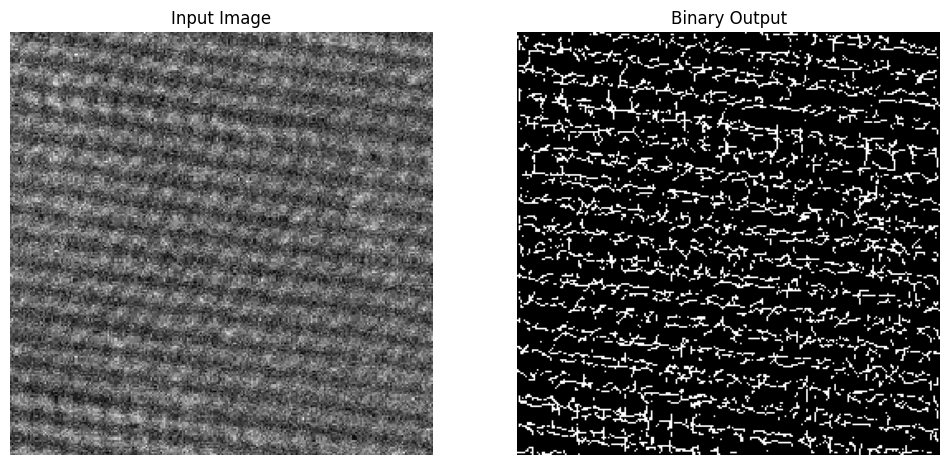

In [447]:
# 可视化原始图像和二值化结果
def visualize_results(original_image_path, binary_image):
    
    # 加载并归一化原始图像
    original_img = load_img(original_image_path, color_mode='grayscale')
    original_img_array = img_to_array(original_img) / 255.0

    # 显示图像
    plt.figure(figsize=(12, 6))

    # 原始图像
    plt.subplot(1, 2, 1)
    plt.imshow(original_img_array.squeeze(), cmap='gray')
    plt.title('Input Image')
    plt.axis('off')

    # 二值化图像
    plt.subplot(1, 2, 2)
    plt.imshow(binary_image, cmap='gray')
    plt.title('Binary Output')
    plt.axis('off')

    plt.show()

# 可视化结果
if processed_img is not None and binary_output is not None:
    visualize_results(IMAGE_PATH, binary_output)

In [448]:
# 保存二值化图像
if binary_output is not None:
    try:
        cv2.imwrite(OUTPUT_IMAGE_PATH, binary_output * 255)  # 转换为 uint8 格式
        print(f"二值化图像已保存至: {OUTPUT_IMAGE_PATH}")
    except Exception as e:
        print(f"保存二值化图像时出错：{e}")

二值化图像已保存至: F:/B208/yyk_dislocation_detection/bi2.png
